11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 56s 29ms/step - accuracy: 0.9342 - loss: 0.2143 - val_accuracy: 0.9840 - val_loss: 0.0496
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 81s 29ms/step - accuracy: 0.9762 - loss: 0.0816 - val_accuracy: 0.9898 - val_loss: 0.0319
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 54s 29ms/step - accuracy: 0.9829 - loss: 0.0588 - val_accuracy: 0.9903 - val_loss: 0.0290
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 29ms/step - accuracy: 0.9858 - loss: 0.0492 - val_accuracy: 0.9913 - val_loss: 0.0261
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 56s 30ms/step - accuracy: 0.9879 - loss: 0.0405 - val_accuracy: 0.9920 - val_loss: 0.0258
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 56s 30ms/step - accuracy: 0.9895 - loss: 0.0330 - val_accuracy: 0.9918 - val_loss: 0.0290
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 80s 29ms/step - accuracy: 0.9913 - loss: 0.0295 - val_accuracy: 0.9917 - val_loss: 0.0256
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 57s 31ms/step - accuracy: 0.9910 -

Model saved successfully!
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9927 - loss: 0.0241
Test Accuracy: 99.27%


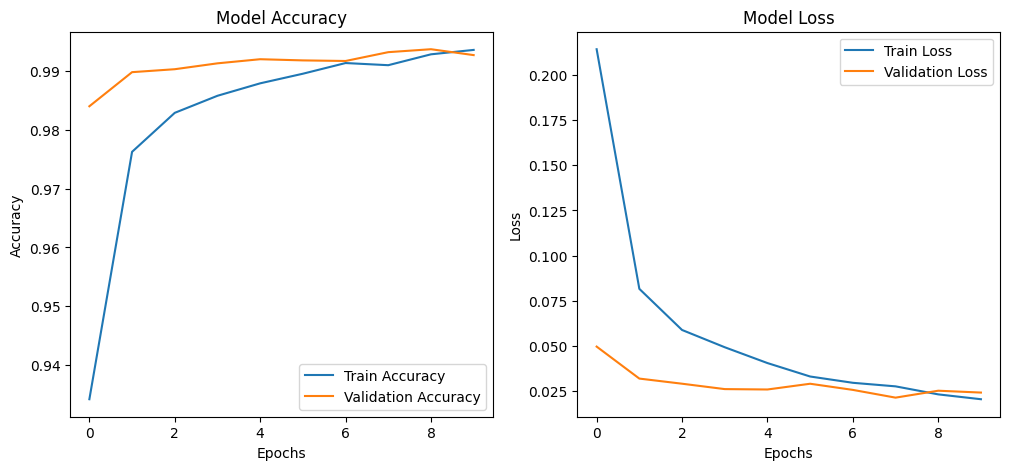

Training history plot saved in results/ folder!


In [1]:
import os
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

# Create directories if they don't exist
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalize pixel values to [0,1]
X_train, X_test = X_train / 255.0, X_test / 255.0

# Reshape images for CNN (28,28,1)
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Convert labels to one-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Define the CNN model
def create_model():
    model = Sequential([
        Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
        MaxPooling2D((2,2)),
        Conv2D(64, (3,3), activation='relu'),
        MaxPooling2D((2,2)),
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Create and train the model
model = create_model()

history = model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test))

# Save the trained model
model.save("models/mnist_model.h5")
print("Model saved successfully!")

# Evaluate the model
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Plot training history
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Model Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.title("Model Loss")

plt.savefig("results/training_history.png")
plt.show()
print("Training history plot saved in results/ folder!")


In [5]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from PIL import Image
import sys

# Load the trained model
model = load_model("models/mnist_model.h5")

def preprocess_image(image_path):
    """Load and preprocess an image for model prediction."""
    img = Image.open(image_path).convert('L')  # Convert to grayscale
    img = img.resize((28, 28))  # Resize to 28x28 pixels
    img = np.array(img) / 255.0  # Normalize pixel values
    img = img.reshape(1, 28, 28, 1)  # Reshape for model input
    return img

def predict_digit(image_path):
    """Predict the digit in the given image."""
    img = preprocess_image(image_path)
    prediction = model.predict(img).argmax()
    return prediction

# Safe argparse handling for Jupyter notebook environments
if __name__ == "__main__" and not hasattr(sys, 'ps1'):
    import argparse
    parser = argparse.ArgumentParser(description="Handwritten Digit Recognition Inference")
    parser.add_argument("--image", type=str, required=True, help="Path to the image file")
    args = parser.parse_args()

    digit = predict_digit(args.image)
    print(f"Predicted Digit: {digit}")
else:
    print("Helper functions successfully loaded! You can now call `predict_digit('your_image_path.png')` in a new cell.")

Helper functions successfully loaded! You can now call `predict_digit('your_image_path.png')` in a new cell.


In [7]:
!pip install -q streamlit

import streamlit as st
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.models import load_model

# Load the trained model
model = load_model("models/mnist_model.h5")

def preprocess_image(image):
    """Preprocess the uploaded image for prediction."""
    img = image.convert('L')  # Convert to grayscale
    img = img.resize((28, 28))  # Resize to 28x28 pixels
    img = np.array(img) / 255.0  # Normalize pixel values
    img = img.reshape(1, 28, 28, 1)  # Reshape for model input
    return img

def predict_digit(image):
    """Predict the digit from the uploaded image."""
    img = preprocess_image(image)
    prediction = model.predict(img).argmax()
    return prediction

# Streamlit UI
st.title("Handwritten Digit Recognition")
st.write("Upload an image of a handwritten digit, and the model will predict the number.")

uploaded_file = st.file_uploader("Choose an image...", type=["png", "jpg", "jpeg"])

if uploaded_file is not None:
    image = Image.open(uploaded_file)
    st.image(image, caption="Uploaded Image", use_column_width=True)
    st.write("Predicting...")

    digit = predict_digit(image)
    st.write(f"Predicted Digit: {digit}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 71.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 109.1 MB/s eta 0:00:00


2026-10-07 08:33:09.111 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-07 08:33:09.222 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-10-07 08:33:09.223 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-07 08:33:09.225 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-07 08:33:09.226 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-07 08:33:09.228 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-07 08:33:09.230 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-07 08:33:09.232 Thread 'MainThread': mi

### **BƯỚC 1: Lưu mã nguồn giao diện thành file `app.py`**
Chạy ô lệnh dưới đây để hệ thống tạo ra file `app.py` lưu trữ ứng dụng Streamlit.

In [8]:
%%writefile app.py
import streamlit as st
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.models import load_model

# Tải model đã huấn luyện
model = load_model("models/mnist_model.h5")

def preprocess_image(image):
    """Tiền xử lý ảnh tải lên."""
    img = image.convert('L')  # Chuyển sang ảnh xám
    img = img.resize((28, 28))  # Đưa về kích thước 28x28
    img = np.array(img) / 255.0  # Chuẩn hóa pixel về [0,1]
    img = img.reshape(1, 28, 28, 1)  # Định dạng đầu vào cho CNN
    return img

def predict_digit(image):
    """Dự đoán chữ số."""
    img = preprocess_image(image)
    prediction = model.predict(img).argmax()
    return prediction

# Giao diện ứng dụng
st.title("Nhận Diện Chữ Số Viết Tay")
st.write("Tải lên ảnh một chữ số viết tay (0-9) để xem AI dự đoán.")

uploaded_file = st.file_uploader("Chọn file ảnh...", type=["png", "jpg", "jpeg"])

if uploaded_file is not None:
    image = Image.open(uploaded_file)
    st.image(image, caption="Ảnh bạn đã tải lên", width=150)
    st.write("Đang phân tích...")

    digit = predict_digit(image)
    st.success(f"Kết quả dự đoán của AI: **{digit}**")

Writing app.py


### **BƯỚC 2: Lấy Mật Khẩu (IP Public) của Colab**
Chạy ô lệnh dưới đây để lấy một chuỗi số IP (Ví dụ: `34.125.85.12`). Bạn hãy **sao chép (Copy)** chuỗi số này lại vì nó sẽ làm mật khẩu để mở trang web.

In [9]:
import urllib.request
print("--- COPY DÃI SỐ NÀY ĐỂ LÀM MẬT KHẨU (PASSWORD) ---")
ip = urllib.request.urlopen('https://ident.me').read().decode('utf8')
print(ip)
print("--------------------------------------------------")

--- COPY DÃI SỐ NÀY ĐỂ LÀM MẬT KHẨU (PASSWORD) ---
34.148.2.67
--------------------------------------------------


### **BƯỚC 3: Khởi chạy Streamlit và tạo link truy cập**
Chạy ô lệnh này để cài đặt `localtunnel`, khởi động Streamlit trong nền và sinh ra đường link demo.

In [10]:
# Cài đặt localtunnel
!npm install -g localtunnel

# Chạy Streamlit ở chế độ nền
import subprocess
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501"])

# Tạo đường hầm kết nối để lấy Link Demo công khai
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏
added 22 packages in 2s
⠏
⠏3 packages are looking for funding
⠏  run `npm fund` for details
⠏⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙your url is: https://kind-mice-rhyme.loca.lt
^C
